# Soal 2c · `reduceByKey` vs `groupByKey().mapValues(sum)`
**Big Data** · **1 driver** di JupyterLab PC Master, memakai **seluruh 16 core** (4 Spark Worker).
Pasangannya **Soal2_Master_Monitor.ipynb** (tab lain): setiap task melapor RUNNING/DONE per PC Worker lewat `pantau()` dengan **jeda 0 detik**, sehingga pengukuran waktu tidak terganggu (kedua versi punya jumlah task yang sama: 32 di tahap 0, 16 di tahap 1).

Pertanyaan (i) dari 2b dijalankan **dua kali dengan dua cara** dalam kondisi yang sama:

| | Versi A: `reduceByKey(add)` | Versi B: `groupByKey().mapValues(sum)` |
|---|---|---|
| Sebelum shuffle (per partisi) | menjumlahkan: `("enwiki", 4000)` | mengumpulkan **list semua nilai**: `("enwiki", [1, 1, 1, ...])` |
| Dikirim lewat shuffle | 1 angka per (partisi, wiki) | **semua 128.869 angka** di dalam list |
| Sisi penerima | menjumlahkan beberapa angka | menampung list besar di memori, baru dijumlahkan |

Catatan PySpark: kolom *Records* shuffle di Spark UI menghitung **potongan data terserialisasi**, bukan pasangan logis, sehingga pembanding utama adalah **byte** (Sel 5) dan jumlah nilai logis yang dikirim (Sel 6).

**Sebelum mulai:**
1. Halaman `http://192.168.1.15:8080` **tidak punya aplikasi aktif** (semua driver 2b sudah `spark.stop()` / kernel dimatikan).
2. Di `Soal2_Master_Monitor.ipynb`: Sel 1 (server), Sel 4 (kosongkan laporan lama), lalu Sel 3 (monitor).
Urutan: **Sel 1 → 7**.

## Sel 1. SparkSession ke cluster (16 core) dan fungsi bantu REST API

In [1]:
# ===== SEL 1: SparkSession (1 driver, 16 core) =====
import os, sys, socket, time, json, uuid, urllib.request
from datetime import datetime
from pathlib import Path
from operator import add
from pyspark import SparkContext
from pyspark.sql import SparkSession

MASTER_IP      = "192.168.1.15"
CORES_MAX      = 16
EXECUTOR_CORES = 4
EXECUTOR_MEM   = "2g"
MIN_PARTISI    = 2 * CORES_MAX         # 32 partisi input
N_SHUFFLE      = CORES_MAX             # 16 partisi shuffle untuk KEDUA versi
DATA_DIR       = "C:/BigData/data/snapshot_wiki"
PAKAI_MONITOR  = True                  # False = tanpa laporan ke monitor
JEDA_PANTAU    = 0                     # 0 agar waktu tidak terganggu (2b memakai 1)
PATH_ASLI      = f"file:///{DATA_DIR}/wiki_snapshot.jsonl"

s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
s.connect((MASTER_IP, 7077)); IP = s.getsockname()[0]; s.close()
EVENT_DIR = Path("spark-events").resolve(); EVENT_DIR.mkdir(exist_ok=True)

old = SparkContext._active_spark_context
if old is not None:
    try: old.stop()
    except Exception: pass
SparkSession._instantiatedSession = None
SparkSession._activeSession = None

spark = (SparkSession.builder
         .appName("Soal2c-reduce-vs-group")
         .master(f"spark://{MASTER_IP}:7077")
         .config("spark.driver.host", IP)
         .config("spark.driver.bindAddress", IP)
         .config("spark.cores.max", str(CORES_MAX))
         .config("spark.executor.cores", str(EXECUTOR_CORES))
         .config("spark.executor.memory", EXECUTOR_MEM)
         .config("spark.pyspark.python", sys.executable)
         .config("spark.pyspark.driver.python", sys.executable)
         .config("spark.ui.port", "4040")
         .config("spark.eventLog.enabled", "true")
         .config("spark.eventLog.dir", EVENT_DIR.as_uri())
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")

def tandai(deskripsi):
    sc.setJobGroup(deskripsi.split()[0], deskripsi)

def api(path):
    """Baca REST API Spark UI driver ini (angka yang sama dengan tab Jobs/Stages)."""
    url = f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}/{path}"
    with urllib.request.urlopen(url, timeout=10) as r:
        return json.load(r)

REPORT_URL = f"http://{MASTER_IP}:8090"

def report(run, app, nomor, status):
    """Dijalankan di executor: kirim status task ke monitor (Soal2_Master_Monitor.ipynb)."""
    import json, os, socket, urllib.request
    data = {"run": run, "app": app, "task": nomor, "worker": socket.gethostname(),
            "pid": os.getpid(), "status": status}
    req = urllib.request.Request(REPORT_URL, data=json.dumps(data).encode("utf-8"),
                                 headers={"Content-Type": "application/json"}, method="POST")
    try:
        with urllib.request.urlopen(req, timeout=5) as r:
            return r.status == 200
    except Exception as e:
        print(f"Gagal melapor ke monitor: {e}")
        return False

def pantau(rdd, label, jeda=JEDA_PANTAU):
    """Pola materi RDD-Cluster: tiap partisi (= task) melapor RUNNING lalu DONE."""
    if not PAKAI_MONITOR:
        return rdd
    run = str(uuid.uuid4())
    def proses_partition(idx, isi):
        import time
        report(run, label, idx, "RUNNING")
        data = list(isi)
        if jeda:
            time.sleep(jeda)
        report(run, label, idx, "DONE")
        return iter(data)
    return rdd.mapPartitionsWithIndex(proses_partition)

if PAKAI_MONITOR:
    try:
        with urllib.request.urlopen(REPORT_URL, timeout=3) as r:
            print("Monitor :", r.read().decode().strip())
    except Exception as e:
        print("PERINGATAN: monitor tidak terjangkau ->", e)
print("Spark   :", spark.version, "|", sc.master, "| driver", IP, "| core", CORES_MAX)
print("Spark UI:", sc.uiWebUrl, "(jika port 4045/4046 -> browser memblokir; tutup driver lain lalu ulang)")
print("App ID  :", sc.applicationId)

Monitor : Monitor aktif. Jumlah laporan: 51
Spark   : 4.1.3 | spark://192.168.1.15:7077 | driver 192.168.1.15 | core 16
Spark UI: http://192.168.1.15:4040 (jika port 4045/4046 -> browser memblokir; tutup driver lain lalu ulang)
App ID  : app-20261118205105-0039


## Sel 2. Input yang sama untuk kedua versi: pasangan `(wiki, 1)` edit manusia, di-cache
Cache diisi lebih dulu dengan `count()`, sehingga kedua versi membaca input dari memori executor dan perbedaan waktunya berasal dari shuffle dan agregasi, bukan dari membaca/parsing file.

In [2]:
# ===== SEL 2: Input bersama (cache) =====
WIKI, ID, TYPE, TITLE, USER, IS_ANON, BOT, MINOR, TS, LEN_OLD, LEN_NEW, COMMENT = range(12)

def _int(x):
    return isinstance(x, int) and not isinstance(x, bool)

def parse(baris):
    import json
    try:
        e = json.loads(baris) if baris.strip() else None
    except ValueError:
        return []
    if not isinstance(e, dict) or not (
            _int(e.get("id")) and _int(e.get("timestamp"))
            and all(isinstance(e.get(k), str) and e.get(k) for k in ("wiki", "type", "title"))):
        return []
    return [(e["wiki"], e["id"], e["type"], e["title"], e.get("user"),
             bool(e.get("is_anon", False)), bool(e.get("bot", False)), bool(e.get("minor", False)),
             e["timestamp"], e.get("length_old"), e.get("length_new"), e.get("comment") or "")]

pasangan = (sc.textFile(PATH_ASLI, minPartitions=MIN_PARTISI)
              .flatMap(parse)
              .filter(lambda r: r[TYPE] == "edit" and not r[BOT])
              .map(lambda r: (r[WIKI], 1))
              .setName("pasangan_wiki_1")
              .cache())

tandai("2c-cache Isi cache pasangan (wiki,1)")
t = time.time(); n_pasangan = pasangan.count(); t_cache = time.time() - t
print(f"Pasangan (wiki, 1): {n_pasangan:,} (pembanding 2b: 128,869) ->", "COCOK" if n_pasangan == 128_869 else "BEDA")
print(f"Partisi input: {pasangan.getNumPartitions()} | waktu mengisi cache: {t_cache:.1f} dtk")
rdd_info = [r for r in api("storage/rdd") if r.get("name") == "pasangan_wiki_1"]
if rdd_info:
    r = rdd_info[0]
    print(f"Cache (tab Storage): {r['numCachedPartitions']}/{r['numPartitions']} partisi, {r['memoryUsed'] / 1e6:.2f} MB di memori")

Pasangan (wiki, 1): 128,869 (pembanding 2b: 128,869) -> COCOK
Partisi input: 32 | waktu mengisi cache: 120.9 dtk
Cache (tab Storage): 32/32 partisi, 0.31 MB di memori


## Sel 3. Versi A: `reduceByKey(add)`
**Tahap 0 (narrow):** input dari cache → `pantau` · **Tahap 1 (wide):** `reduceByKey` → `pantau` → `takeOrdered(10)` (action)

In [3]:
# ===== SEL 3: Versi A - reduceByKey =====
tandai("2c-reduceByKey (i) dengan reduceByKey")
t = time.time()
tahap0_A = pantau(pasangan, "2c-A tahap 0: input cache (narrow)")
tahap1_A = pantau(tahap0_A.reduceByKey(add, N_SHUFFLE), "2c-A tahap 1: reduceByKey (wide)")
top_A = tahap1_A.takeOrdered(10, key=lambda kv: (-kv[1], kv[0]))
waktu_A = time.time() - t
for i, (w, n) in enumerate(top_A, 1):
    print(f"{i:>3}. {w:<22}{n:>8,}")
print(f"\nWaktu Versi A (reduceByKey): {waktu_A:.2f} dtk")

  1. wikidatawiki            72,409
  2. commonswiki             17,990
  3. enwiki                  17,403
  4. frwiki                   2,424
  5. dewiki                   2,394
  6. eswiki                   1,494
  7. itwiki                   1,458
  8. ptwiki                   1,145
  9. zhwiki                     986
 10. ruwiki                     958

Waktu Versi A (reduceByKey): 518.24 dtk


## Sel 4. Versi B: `groupByKey().mapValues(sum)`
**Tahap 0 (narrow):** input dari cache → `pantau` · **Tahap 1 (wide):** `groupByKey` → `mapValues(sum)` → `pantau` → `takeOrdered(10)` (action)

In [4]:
# ===== SEL 4: Versi B - groupByKey().mapValues(sum) =====
tandai("2c-groupByKey (i) dengan groupByKey().mapValues(sum)")
t = time.time()
tahap0_B = pantau(pasangan, "2c-B tahap 0: input cache (narrow)")
tahap1_B = pantau(tahap0_B.groupByKey(N_SHUFFLE).mapValues(sum), "2c-B tahap 1: groupByKey+mapValues (wide)")
top_B = tahap1_B.takeOrdered(10, key=lambda kv: (-kv[1], kv[0]))
waktu_B = time.time() - t
for i, (w, n) in enumerate(top_B, 1):
    print(f"{i:>3}. {w:<22}{n:>8,}")
print(f"\nWaktu Versi B (groupByKey): {waktu_B:.2f} dtk")
print("\nHasil A dan B sama:", top_A == [tuple(x) for x in top_B])

f2b = Path("hasil_2b/driver1.json")
if f2b.exists():
    top_2b = [tuple(x) for x in json.loads(f2b.read_text(encoding="utf-8"))["i"]]
    print("Sama dengan jawaban 2b(i) driver 1:", top_2b == top_A)

  1. wikidatawiki            72,409
  2. commonswiki             17,990
  3. enwiki                  17,403
  4. frwiki                   2,424
  5. dewiki                   2,394
  6. eswiki                   1,494
  7. itwiki                   1,458
  8. ptwiki                   1,145
  9. zhwiki                     986
 10. ruwiki                     958

Waktu Versi B (groupByKey): 128.15 dtk

Hasil A dan B sama: True
Sama dengan jawaban 2b(i) driver 1: True


## Sel 5. Waktu dan Shuffle Write/Read per stage (dari REST API Spark UI)
Angka di tabel ini sama dengan tab **Stages** Spark UI. Ambil juga screenshot tab Stages sebagai lampiran.

In [5]:
# ===== SEL 5: Metrik shuffle per stage =====
def waktu_ms(a, b):
    f = lambda s: datetime.strptime(s.replace("GMT", ""), "%Y-%m-%dT%H:%M:%S.%f")
    try:
        return (f(b) - f(a)).total_seconds() * 1000
    except Exception:
        return None

def metrik(grup):
    jobs = [j for j in api("jobs") if j.get("jobGroup") == grup or str(j.get("description", "")).startswith(grup)]
    baris = []
    for j in jobs:
        for sid in sorted(j["stageIds"]):
            st = api(f"stages/{sid}")[0]
            baris.append({
                "stage": sid, "nama": st.get("name", "")[:38], "task": st.get("numTasks"),
                "durasi_ms": waktu_ms(st.get("submissionTime"), st.get("completionTime")),
                "sw_byte": st.get("shuffleWriteBytes", 0), "sw_rec": st.get("shuffleWriteRecords", 0),
                "sr_byte": st.get("shuffleReadBytes", 0), "sr_rec": st.get("shuffleReadRecords", 0),
            })
    return baris

def kb(x):
    return f"{x / 1024:,.1f} KB"

ringkas = {}
for label, grup, waktu in (("A reduceByKey", "2c-reduceByKey", waktu_A), ("B groupByKey", "2c-groupByKey", waktu_B)):
    baris = metrik(grup)
    print(f"\n=== {label} | waktu job (driver) {waktu:.2f} dtk ===")
    print(f"{'stage':>5}  {'nama':<38}{'task':>5}{'durasi':>9}{'Shuffle Write':>16}{'rec':>7}{'Shuffle Read':>16}{'rec':>7}")
    for b in baris:
        d = f"{b['durasi_ms'] / 1000:.2f}s" if b["durasi_ms"] is not None else "-"
        print(f"{b['stage']:>5}  {b['nama']:<38}{b['task']:>5}{d:>9}{kb(b['sw_byte']):>16}{b['sw_rec']:>7}{kb(b['sr_byte']):>16}{b['sr_rec']:>7}")
    ringkas[label] = {"waktu": waktu, "sw": sum(b["sw_byte"] for b in baris), "sr": sum(b["sr_byte"] for b in baris)}

A, B = ringkas["A reduceByKey"], ringkas["B groupByKey"]
print("\n===== PERBANDINGAN =====")
print(f"{'':<14}{'reduceByKey':>14}{'groupByKey':>14}{'B / A':>8}")
print(f"{'Waktu (dtk)':<14}{A['waktu']:>14.2f}{B['waktu']:>14.2f}{B['waktu'] / A['waktu']:>8.2f}x")
print(f"{'Shuffle Write':<14}{kb(A['sw']):>14}{kb(B['sw']):>14}{B['sw'] / max(A['sw'], 1):>8.1f}x")
print(f"{'Shuffle Read':<14}{kb(A['sr']):>14}{kb(B['sr']):>14}{B['sr'] / max(A['sr'], 1):>8.1f}x")


=== A reduceByKey | waktu job (driver) 518.24 dtk ===
stage  nama                                   task   durasi   Shuffle Write    rec    Shuffle Read    rec
    1  reduceByKey at C:\Users\Administrator\   32  110.72s         61.0 KB    509          0.0 KB      0
    2  takeOrdered at C:\Users\Administrator\   16   99.74s          0.0 KB      0         43.6 KB    365

=== B groupByKey | waktu job (driver) 128.15 dtk ===
stage  nama                                   task   durasi   Shuffle Write    rec    Shuffle Read    rec
    3  groupByKey at C:\Users\Administrator\A   32   15.91s         67.3 KB    509          0.0 KB      0
    4  takeOrdered at C:\Users\Administrator\   16   99.39s          0.0 KB      0         55.5 KB    414

===== PERBANDINGAN =====
                 reduceByKey    groupByKey   B / A
Waktu (dtk)           518.24        128.15    0.25x
Shuffle Write        61.0 KB       67.3 KB     1.1x
Shuffle Read         43.6 KB       55.5 KB     1.3x


## Sel 6. Apa yang sebenarnya dikirim lewat shuffle (perhitungan logis)
Menghitung, untuk tiap partisi input, berapa kunci dan berapa nilai yang ikut terkirim pada masing-masing versi.

In [6]:
# ===== SEL 6: Isi shuffle secara logis =====
def per_partisi(it):
    hitung = {}
    for k, v in it:
        hitung[k] = hitung.get(k, 0) + 1
    yield (len(hitung), sum(hitung.values()))       # (kunci unik di partisi ini, nilai di partisi ini)

tandai("2c-logis Hitung isi shuffle per partisi")
p = pasangan.mapPartitions(per_partisi).collect()
kunci_parsial = sum(a for a, _ in p)
nilai_total = sum(b for _, b in p)
print(f"Partisi input                          : {len(p)}")
print(f"Pasangan (kunci, nilai) di input       : {nilai_total:,}")
print(f"Kelompok (partisi, wiki) yang dikirim  : {kunci_parsial:,}  (sama untuk kedua versi)")
print(f"Nilai yang dikirim - reduceByKey       : {kunci_parsial:,}  (1 angka jumlah per kelompok)")
print(f"Nilai yang dikirim - groupByKey        : {nilai_total:,}  (semua angka 1 di dalam list)")
print(f"Rasio nilai terkirim groupByKey/reduce : {nilai_total / kunci_parsial:,.1f}x")

Partisi input                          : 32
Pasangan (kunci, nilai) di input       : 128,869
Kelompok (partisi, wiki) yang dikirim  : 2,259  (sama untuk kedua versi)
Nilai yang dikirim - reduceByKey       : 2,259  (1 angka jumlah per kelompok)
Nilai yang dikirim - groupByKey        : 128,869  (semua angka 1 di dalam list)
Rasio nilai terkirim groupByKey/reduce : 57.0x


## Sel 7. Grafik perbandingan dan penutup

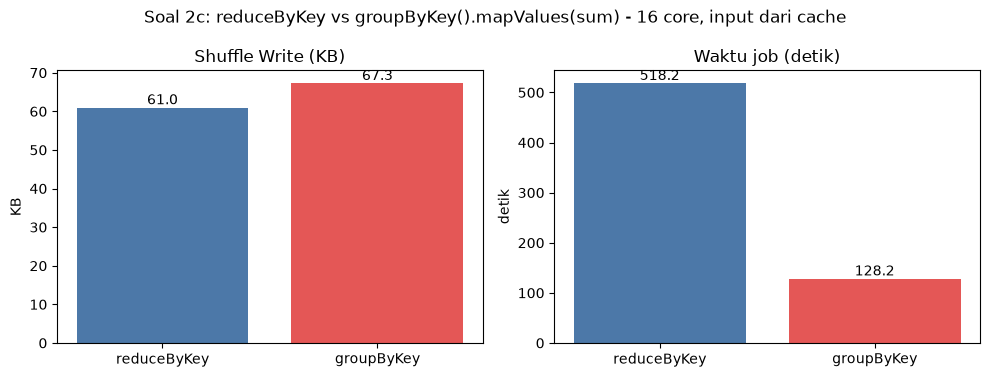

Spark UI: http://192.168.1.15:4040 -> Jobs: 2c-reduceByKey dan 2c-groupByKey -> Stages (Shuffle Write/Read) -> DAG
Monitor : lihat bagian PER WORKER di Soal2_Master_Monitor.ipynb (task 2c-A dan 2c-B per PC)


In [7]:
# ===== SEL 7: Grafik dan penutup =====
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
label = ["reduceByKey", "groupByKey"]
ax[0].bar(label, [A["sw"] / 1024, B["sw"] / 1024], color=["#4C78A8", "#E45756"])
ax[0].set(title="Shuffle Write (KB)", ylabel="KB")
ax[1].bar(label, [A["waktu"], B["waktu"]], color=["#4C78A8", "#E45756"])
ax[1].set(title="Waktu job (detik)", ylabel="detik")
for a in ax:
    for c in a.containers:
        a.bar_label(c, fmt="%.1f")
fig.suptitle("Soal 2c: reduceByKey vs groupByKey().mapValues(sum) - 16 core, input dari cache")
fig.tight_layout()
Path("laporan").mkdir(exist_ok=True)
fig.savefig("laporan/2c_reduce_vs_group.png", dpi=120)
plt.show()

print("Spark UI:", sc.uiWebUrl, "-> Jobs: 2c-reduceByKey dan 2c-groupByKey -> Stages (Shuffle Write/Read) -> DAG")
print("Monitor : lihat bagian PER WORKER di Soal2_Master_Monitor.ipynb (task 2c-A dan 2c-B per PC)")
# pasangan.unpersist(); spark.stop()   # buka komentar setelah screenshot selesai